In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Student_Performance_2026.csv to Student_Performance_2026.csv


In [ ]:
import pandas as pd

df = pd.read_csv("Student_Performance_2026.csv")

df.info()

df.describe()

print(df.isnull().sum())



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 546 entries, 0 to 545
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   student_ID               546 non-null    object 
 1   Age                      546 non-null    int64  
 2   Gender                   546 non-null    object 
 3   daily_screen_time_hours  546 non-null    float64
 4   social_media_hours       546 non-null    float64
 5   online_study_hours       546 non-null    float64
 6   gaming_hours             546 non-null    float64
 7   sleep_hours              546 non-null    float64
 8   attendance_percentage    546 non-null    int64  
 9   offline_study_hours      546 non-null    float64
 10  previous_sem_CGPA        546 non-null    float64
 11  current_sem_CGPA         546 non-null    float64
dtypes: float64(8), int64(2), object(2)
memory usage: 51.3+ KB
student_ID                 0
Age                        0
Gender            

In [ ]:
df.head()


,student_ID,Age,Gender,daily_screen_time_hours,social_media_hours,online_study_hours,gaming_hours,sleep_hours,attendance_percentage,offline_study_hours,previous_sem_CGPA,current_sem_CGPA
0,S011,23,Female,6.2,2.5,3.8,1.2,7.1,79,2.6,7.74,7.94
1,S012,24,Female,4.9,2.0,5.1,1.0,8.3,79,2.6,7.72,7.92
2,S013,18,Female,7.9,3.2,2.1,1.6,7.1,68,2.3,6.67,6.87
3,S014,17,Male,10.0,4.0,0.0,2.0,5.9,63,2.1,6.10,6.30
4,S015,23,Female,7.7,3.1,2.3,1.5,6.4,69,2.3,6.77,6.97


# Cleaning

In [ ]:
# I am cleaning my data
# if there is some missing values
print(df.isnull().sum())

df["student_ID"].duplicated().sum() #because two students can share the same grade or screen time etc .. but not the same ID.

print(df.dtypes) # checking the data type if everythings works well

print(df.columns)

print(df["Gender"].unique()) # to be sure to have only male or female

student_ID                 0
Age                        0
Gender                     0
daily_screen_time_hours    0
social_media_hours         0
online_study_hours         0
gaming_hours               0
sleep_hours                0
attendance_percentage      0
offline_study_hours        0
previous_sem_CGPA          0
current_sem_CGPA           0
dtype: int64
student_ID                  object
Age                          int64
Gender                      object
daily_screen_time_hours    float64
social_media_hours         float64
online_study_hours         float64
gaming_hours               float64
sleep_hours                float64
attendance_percentage        int64
offline_study_hours        float64
previous_sem_CGPA          float64
current_sem_CGPA           float64
dtype: object
Index(['student_ID', 'Age', 'Gender', 'daily_screen_time_hours',
       'social_media_hours', 'online_study_hours', 'gaming_hours',
       'sleep_hours', 'attendance_percentage', 'offline_study_hours',
   

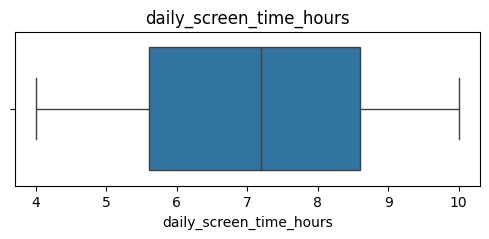

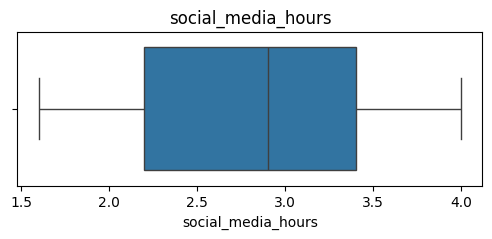

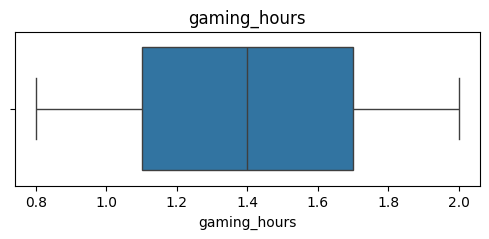

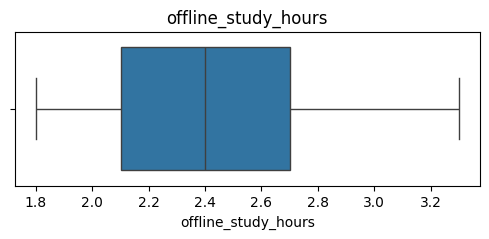

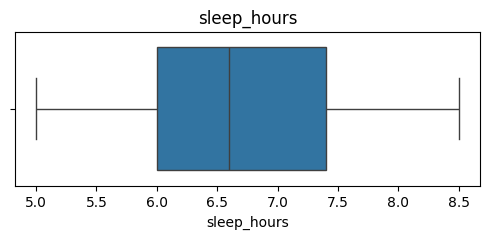

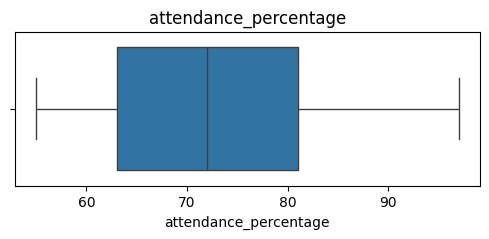

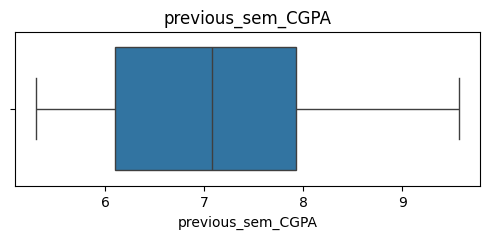

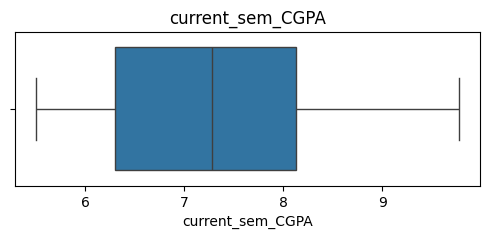

In [ ]:
#for cleaning the data i also want to check if there any outliers. there is two ways
#1st way:
import seaborn as sns
import matplotlib.pyplot as plt

columns = [
    "daily_screen_time_hours",
    "social_media_hours",
    "gaming_hours",
    "offline_study_hours",
    "sleep_hours",
    "attendance_percentage",
    "previous_sem_CGPA",
    "current_sem_CGPA"
]

for col in columns:
    plt.figure(figsize=(6,2))
    sns.boxplot(x=df[col])
    plt.title(col)

plt.show()

I am checking if there is any outlier. if there is one point pretty far from the average zone i could be an outlier. (here everythings is fine)

In [ ]:
# 2nd way to detect outliers.(with IQR)
columns = [
    "daily_screen_time_hours",
    "social_media_hours",
    "gaming_hours",
    "offline_study_hours",
    "sleep_hours",
    "attendance_percentage",
    "previous_sem_CGPA",
    "current_sem_CGPA"
]

for col in columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) |
        (df[col] > upper)
    ]

    print(f"{col}: {outliers.shape[0]} outliers")

daily_screen_time_hours: 0 outliers
social_media_hours: 0 outliers
gaming_hours: 0 outliers
offline_study_hours: 0 outliers
sleep_hours: 0 outliers
attendance_percentage: 0 outliers
previous_sem_CGPA: 0 outliers
current_sem_CGPA: 0 outliers


With the df.describe just below, we have Q1,Q2 and Q3.
So we calcul IQR (IQR = Q3-Q1) and then we calcul the range with the  lower = Q1 - 1.5 * IQR and Upper = Q3 + 1.5 * IQR.
And everything under or over this range is considered like outlier. (here everything is fine)

# EDA

In [ ]:
print(df.describe())


              Age  daily_screen_time_hours  social_media_hours  \
count  546.000000               546.000000          546.000000   
mean    20.946886                 7.109341            2.843773   
std      2.587713                 1.774872            0.712978   
min     17.000000                 4.000000            1.600000   
25%     19.000000                 5.600000            2.200000   
50%     21.000000                 7.200000            2.900000   
75%     23.000000                 8.600000            3.400000   
max     25.000000                10.000000            4.000000   

       online_study_hours  gaming_hours  sleep_hours  attendance_percentage  \
count          546.000000    546.000000   546.000000             546.000000   
mean             2.890659      1.422711     6.696886              72.970696   
std              1.774872      0.357921     0.947197              11.747772   
min              0.000000      0.800000     5.000000              55.000000   
25%       

In [ ]:
print(df.corr(numeric_only=True))

                              Age  daily_screen_time_hours  \
Age                      1.000000                 0.020842   
daily_screen_time_hours  0.020842                 1.000000   
social_media_hours       0.021153                 0.999275   
online_study_hours      -0.020842                -1.000000   
gaming_hours             0.022502                 0.996868   
sleep_hours              0.002253                -0.843909   
attendance_percentage    0.016970                -0.875980   
offline_study_hours      0.021525                -0.873436   
previous_sem_CGPA        0.018070                -0.875822   
current_sem_CGPA         0.018070                -0.875822   

                         social_media_hours  online_study_hours  gaming_hours  \
Age                                0.021153           -0.020842      0.022502   
daily_screen_time_hours            0.999275           -1.000000      0.996868   
social_media_hours                 1.000000           -0.999275      0.995

I am explaining very clearly what this output means in my project part EDA.

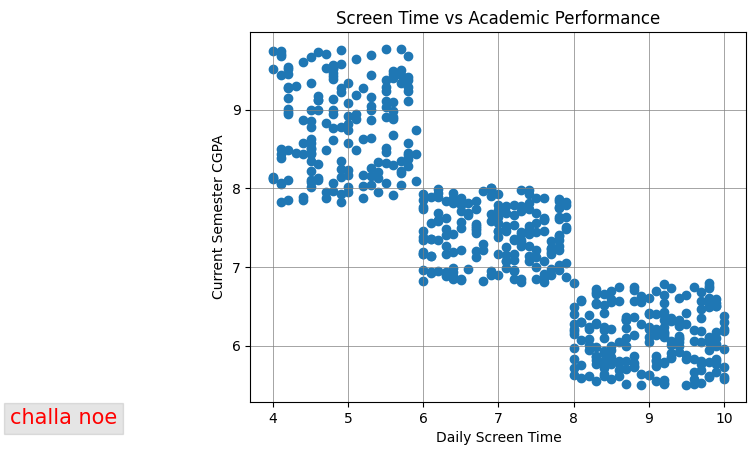

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(df["daily_screen_time_hours"], df["current_sem_CGPA"])

plt.xlabel("Daily Screen Time")
plt.ylabel("Current Semester CGPA")
plt.title("Screen Time vs Academic Performance")
plt.text(0.5, 5, "challa noe", color = 'r', fontsize=15,bbox={'facecolor': 'black', 'alpha':0.1})
plt.grid(axis='y', color='grey', linewidth=0.5)
plt.grid(axis='x', color='grey', linewidth=0.5)

plt.show()

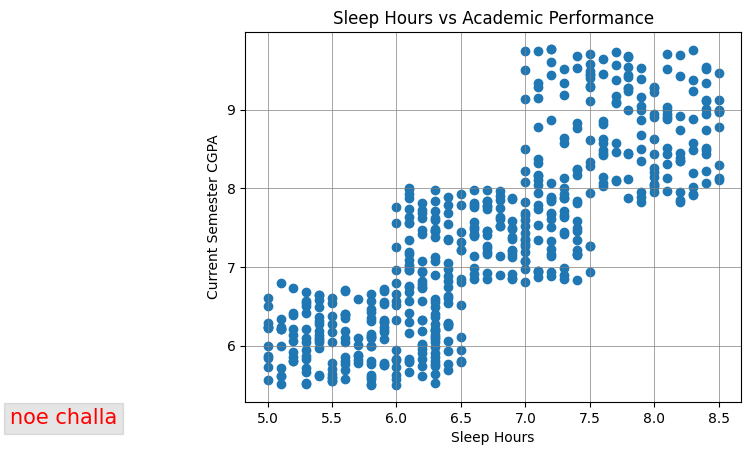

In [ ]:
plt.scatter(df["sleep_hours"], df["current_sem_CGPA"])

plt.xlabel("Sleep Hours")
plt.ylabel("Current Semester CGPA")
plt.title("Sleep Hours vs Academic Performance")
plt.text(3, 5, "noe challa", color = 'r', fontsize=15,bbox={'facecolor': 'black', 'alpha':0.1})
plt.grid(axis='y', color='grey', linewidth=0.5)
plt.grid(axis='x', color='grey', linewidth=0.5)

plt.show()

And below it is the visualisation with every other variable (without gender because it is categorical variable and the age become it has a very weak correlation)  )

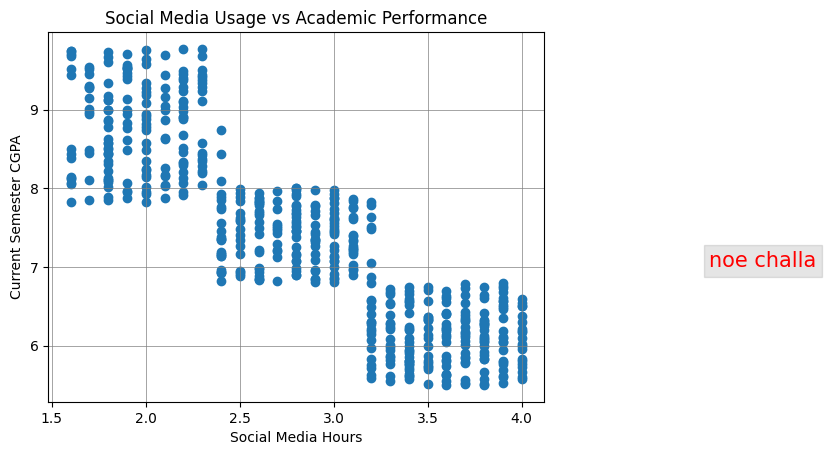

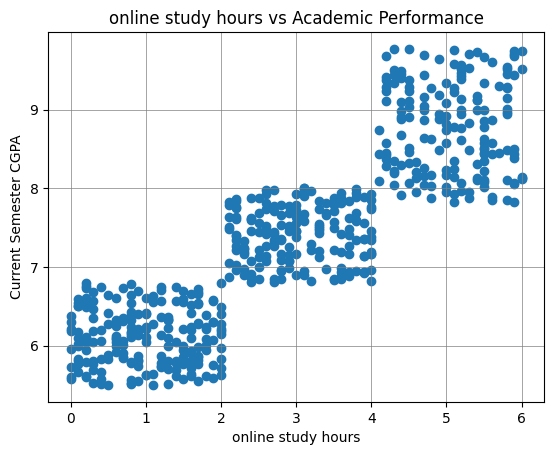

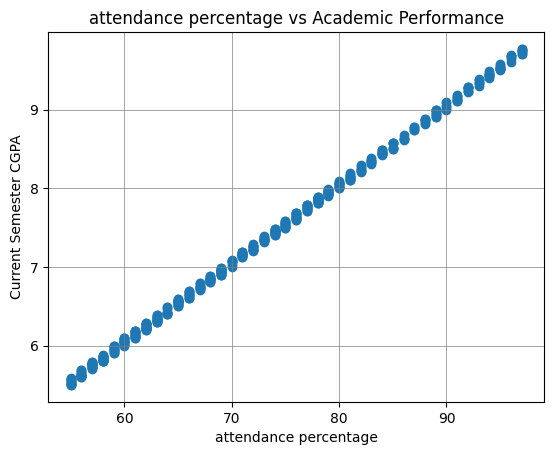

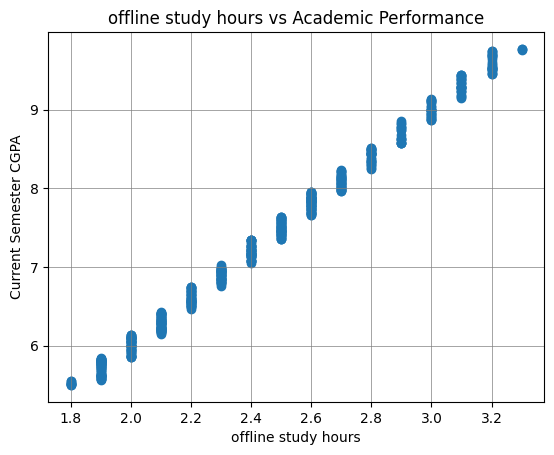

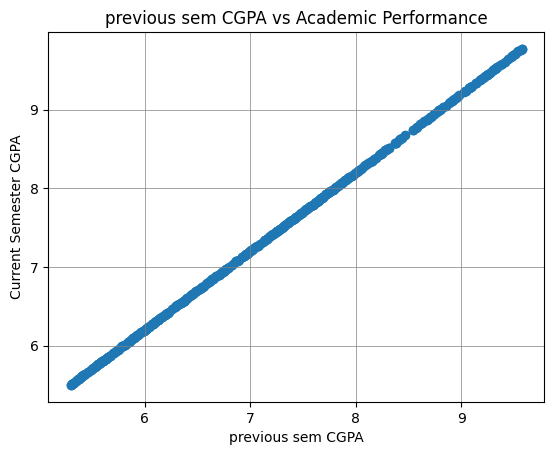

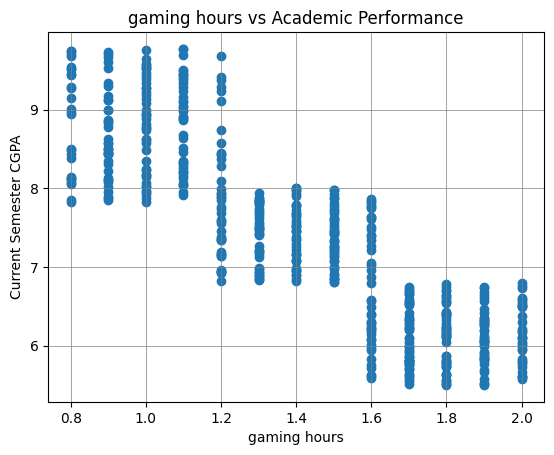

In [ ]:
# Visualisation with Social Media Hours
plt.scatter(df["social_media_hours"], df["current_sem_CGPA"])

plt.xlabel("Social Media Hours")
plt.ylabel("Current Semester CGPA")
plt.title("Social Media Usage vs Academic Performance")
plt.text(5, 7, "noe challa", color = 'r', fontsize=15,bbox={'facecolor': 'black', 'alpha':0.1})
plt.grid(axis='y', color='grey', linewidth=0.5)
plt.grid(axis='x', color='grey', linewidth=0.5)

plt.show()

#with online study hours
plt.scatter(df["online_study_hours"], df["current_sem_CGPA"])

plt.xlabel("online study hours")
plt.ylabel("Current Semester CGPA")
plt.title("online study hours vs Academic Performance")
plt.grid(axis='y', color='grey', linewidth=0.5)
plt.grid(axis='x', color='grey', linewidth=0.5)

plt.show()

#with attendance_percentage

plt.scatter(df["attendance_percentage"], df["current_sem_CGPA"])

plt.xlabel("attendance percentage")
plt.ylabel("Current Semester CGPA")
plt.title("attendance percentage vs Academic Performance")
plt.grid(axis='y', color='grey', linewidth=0.5)
plt.grid(axis='x', color='grey', linewidth=0.5)

plt.show()

#with offline study hours

plt.scatter(df["offline_study_hours"], df["current_sem_CGPA"])

plt.xlabel("offline study hours")
plt.ylabel("Current Semester CGPA")
plt.title("offline study hours vs Academic Performance")
plt.grid(axis='y', color='grey', linewidth=0.5)
plt.grid(axis='x', color='grey', linewidth=0.5)

plt.show()

#with previous CGPA

plt.scatter(df["previous_sem_CGPA"], df["current_sem_CGPA"])

plt.xlabel("previous sem CGPA")
plt.ylabel("Current Semester CGPA")
plt.title("previous sem CGPA vs Academic Performance")
plt.grid(axis='y', color='grey', linewidth=0.5)
plt.grid(axis='x', color='grey', linewidth=0.5)

plt.show()

#with gaming hours

plt.scatter(df["gaming_hours"], df["current_sem_CGPA"])

plt.xlabel("gaming hours")
plt.ylabel("Current Semester CGPA")
plt.title("gaming hours vs Academic Performance")
plt.grid(axis='y', color='grey', linewidth=0.5)
plt.grid(axis='x', color='grey', linewidth=0.5)

plt.show()


I am interpreting very clearly what those Visualisations means in my project.pdf in part Interpretation.

In [ ]:
correlation = df.corr(numeric_only=True)

print(correlation["current_sem_CGPA"].sort_values(ascending=False))

previous_sem_CGPA          1.000000
current_sem_CGPA           1.000000
attendance_percentage      0.999703
offline_study_hours        0.997367
online_study_hours         0.875822
sleep_hours                0.822879
Age                        0.018070
gaming_hours              -0.868207
social_media_hours        -0.875532
daily_screen_time_hours   -0.875822
Name: current_sem_CGPA, dtype: float64


It shows the correlation between every variables and the current CGPA

# ML

In [ ]:
X = df.drop(columns=["student_ID", "current_sem_CGPA"])
y = df["current_sem_CGPA"]

X = pd.get_dummies(X, drop_first=True)

I drop student ID because it is useless and i drop current CGPA because it is this one i want to predict.
And i transforme male/female by binary number to make it readable

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [ ]:
# Multiple Linear Regression - Google Colab Version

# Import libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load dataset
# Replace with your file name
df = pd.read_csv("Student_Performance_2026.csv")

# Input features (independent variables)
X = df[
    [
        "daily_screen_time_hours",
        "social_media_hours",
        "gaming_hours",
        "offline_study_hours",
        "sleep_hours",
        "attendance_percentage",
        "previous_sem_CGPA"
    ]
]

# Target variable (dependent variable)
y = df["current_sem_CGPA"]

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Create the model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Display coefficients
print("Model Coefficients:")
for feature, coef in zip(X.columns, model.coef_):
    print(f"{feature}: {coef}")

# Display intercept
print("\nIntercept:")
print(model.intercept_)

# Evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nModel Evaluation:")
print(f"MAE: {mae}")
print(f"MSE: {mse}")
print(f"RMSE: {rmse}")
print(f"R2 Score: {r2}")

# Compare actual vs predicted values
results = pd.DataFrame({
    "Actual CGPA": y_test,
    "Predicted CGPA": y_pred
})

print("\nPredictions:")
print(results.head(10))

Model Coefficients:
daily_screen_time_hours: 4.988578163715439e-16
social_media_hours: 2.5396351688300456e-15
gaming_hours: -1.7351571568458013e-15
offline_study_hours: -4.980824780398407e-15
sleep_hours: 2.8189256484623115e-15
attendance_percentage: 7.494005416219807e-16
previous_sem_CGPA: 0.9999999999999926

Intercept:
0.19999999999998508

Model Evaluation:
MAE: 2.3577099868403326e-15
MSE: 1.0298220544521572e-29
RMSE: 3.209084066290812e-15
R2 Score: 1.0

Predictions:
     Actual CGPA  Predicted CGPA
316         6.94            6.94
77          5.81            5.81
360         8.88            8.88
90          6.90            6.90
495         9.22            9.22
209         5.58            5.58
176         5.79            5.79
249         8.01            8.01
517         5.76            5.76
489         6.58            6.58


R2 Score: 1.0
MAE: 2.3577099868403326e-15
RMSE: 3.209084066290812e-15


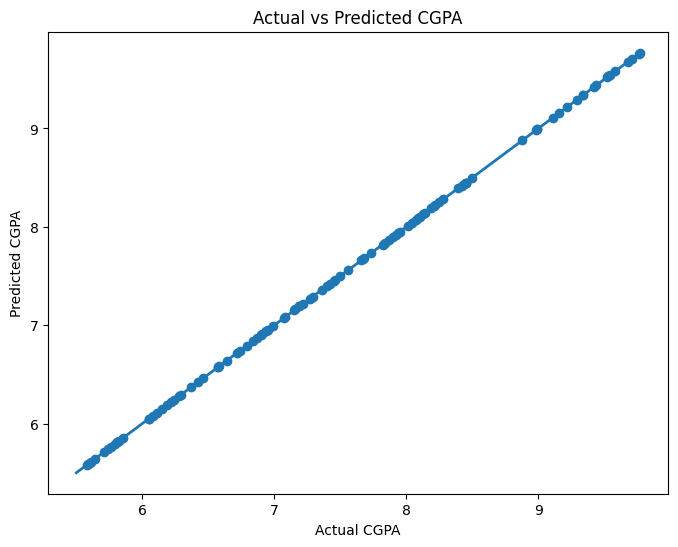

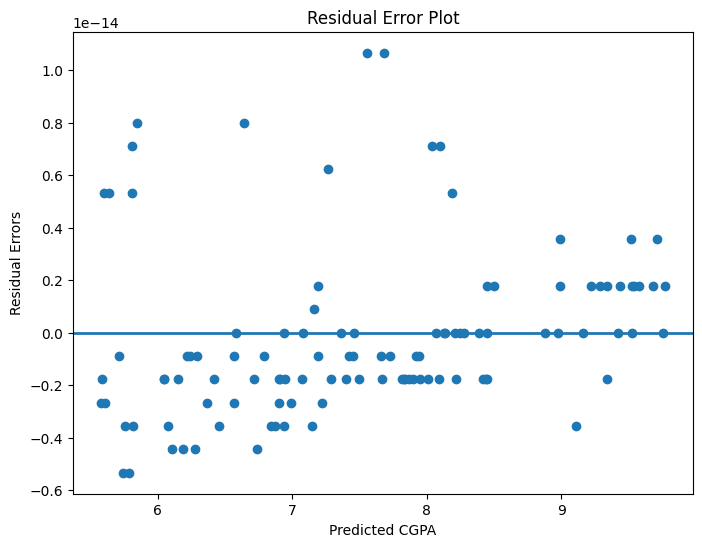

In [ ]:
# Multiple Linear Regression with Graphs

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load dataset
df = pd.read_csv("Student_Performance_2026.csv")

# Features
X = df[
    [
        "daily_screen_time_hours",
        "social_media_hours",
        "gaming_hours",
        "offline_study_hours",
        "sleep_hours",
        "attendance_percentage",
        "previous_sem_CGPA"
    ]
]

# Target
y = df["current_sem_CGPA"]

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Create and train model
model = LinearRegression()
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

# Metrics
print("R2 Score:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

# -----------------------------
# GRAPH 1 : Actual vs Predicted
# -----------------------------

plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred)

plt.plot(
    [y.min(), y.max()],
    [y.min(), y.max()],
    linewidth=2
)

plt.xlabel("Actual CGPA")
plt.ylabel("Predicted CGPA")
plt.title("Actual vs Predicted CGPA")

plt.show()

# -----------------------------------
# GRAPH 2 : Residual Errors
# -----------------------------------

residuals = y_test - y_pred

plt.figure(figsize=(8,6))

plt.scatter(y_pred, residuals)

plt.axhline(y=0, linewidth=2)

plt.xlabel("Predicted CGPA")
plt.ylabel("Residual Errors")
plt.title("Residual Error Plot")

plt.show()